In [56]:
"""
Try a Support Vector Machine regressor (sklearn.svm.SVR) with various hyper‐
parameters, such as kernel="linear" (with various values for the C hyperpara‐
meter) or kernel="rbf" (with various values for the C and gamma
hyperparameters). Don’t worry about what these hyperparameters mean for now.
How does the best SVR predictor perform?

2. Try replacing GridSearchCV with RandomizedSearchCV.

3. Try adding a transformer in the preparation pipeline to select only the most
important attributes.

4. Try creating a single pipeline that does the full data preparation plus the final
prediction.

5. Automatically explore some preparation options using GridSearchCV
"""

'\nTry a Support Vector Machine regressor (sklearn.svm.SVR) with various hyper‐\nparameters, such as kernel="linear" (with various values for the C hyperpara‐\nmeter) or kernel="rbf" (with various values for the C and gamma\nhyperparameters). Don’t worry about what these hyperparameters mean for now.\nHow does the best SVR predictor perform?\n\n2. Try replacing GridSearchCV with RandomizedSearchCV.\n\n3. Try adding a transformer in the preparation pipeline to select only the most\nimportant attributes.\n\n4. Try creating a single pipeline that does the full data preparation plus the final\nprediction.\n\n5. Automatically explore some preparation options using GridSearchCV\n'

In [57]:
import numpy as np
import pandas as pd


In [58]:
data = pd.read_csv(r'../datasets/housing/housing.csv')
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<Axes: xlabel='population', ylabel='median_house_value'>

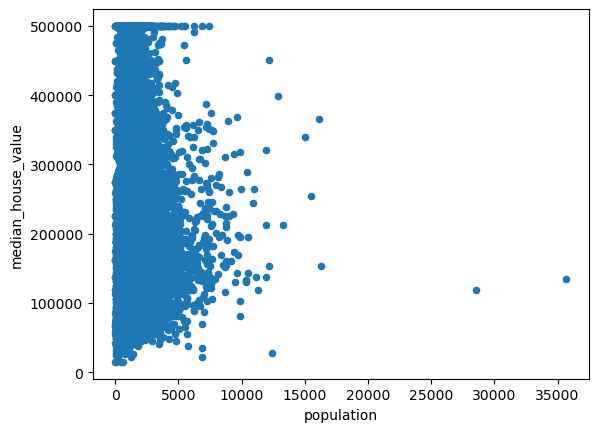

In [59]:
data.plot(kind='scatter',x='population',y='median_house_value')

In [60]:
data=data.dropna()

In [61]:
corr_data_check = data.drop(columns=['ocean_proximity'])
corr = corr_data_check.corr()
corr

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924616,-0.109357,0.045480,0.069608,0.100270,0.056513,-0.015550,-0.045398
latitude,-0.924616,1.000000,0.011899,-0.036667,-0.066983,-0.108997,-0.071774,-0.079626,-0.144638
housing_median_age,-0.109357,0.011899,1.000000,-0.360628,-0.320451,-0.295787,-0.302768,-0.118278,0.106432
total_rooms,0.045480,-0.036667,-0.360628,1.000000,0.930380,0.857281,0.918992,0.197882,0.133294
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.100270,-0.108997,-0.295787,0.857281,0.877747,1.000000,0.907186,0.005087,-0.025300
households,0.056513,-0.071774,-0.302768,0.918992,0.979728,0.907186,1.000000,0.013434,0.064894
median_income,-0.015550,-0.079626,-0.118278,0.197882,-0.007723,0.005087,0.013434,1.000000,0.688355
median_house_value,-0.045398,-0.144638,0.106432,0.133294,0.049686,-0.025300,0.064894,0.688355,1.000000


In [62]:
col = [c for c in corr_data_check.columns]
for c in col:
    print("*"*50)
    print("For column:",c)
    sortcol = corr[c].sort_values(ascending=False)[1:].head(1)
    print(sortcol)
    print("*"*50)


**************************************************
For column: longitude
population    0.10027
Name: longitude, dtype: float64
**************************************************
**************************************************
For column: latitude
housing_median_age    0.011899
Name: latitude, dtype: float64
**************************************************
**************************************************
For column: housing_median_age
median_house_value    0.106432
Name: housing_median_age, dtype: float64
**************************************************
**************************************************
For column: total_rooms
total_bedrooms    0.93038
Name: total_rooms, dtype: float64
**************************************************
**************************************************
For column: total_bedrooms
households    0.979728
Name: total_bedrooms, dtype: float64
**************************************************
**************************************************
For co

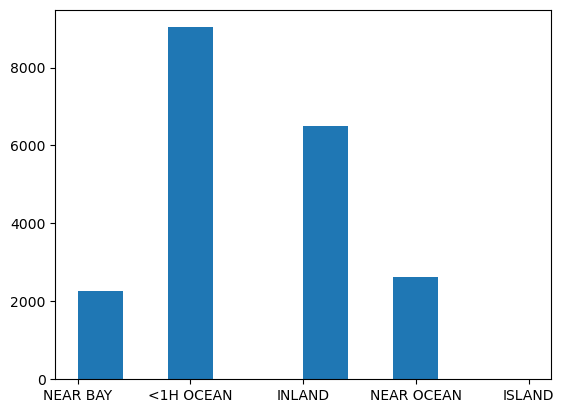

In [63]:
import matplotlib.pyplot as plt
plt.hist(x=data['ocean_proximity'])
plt.show()

For column: longitude
longitude


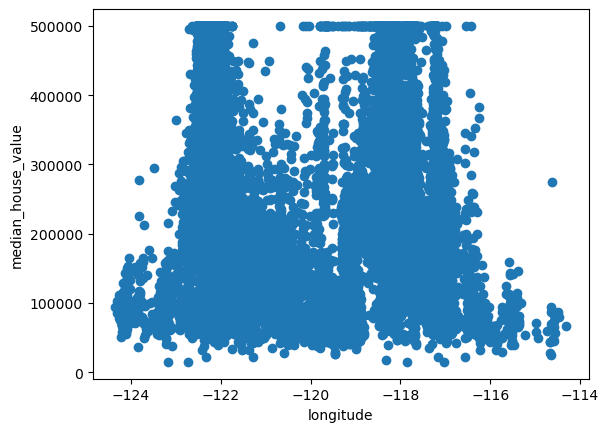

For column: latitude
latitude


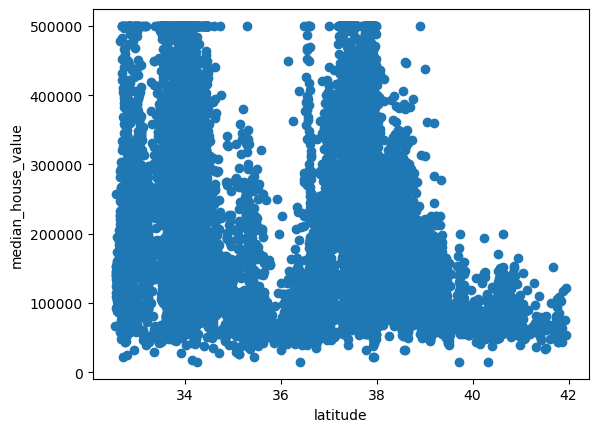

For column: housing_median_age
housing_median_age


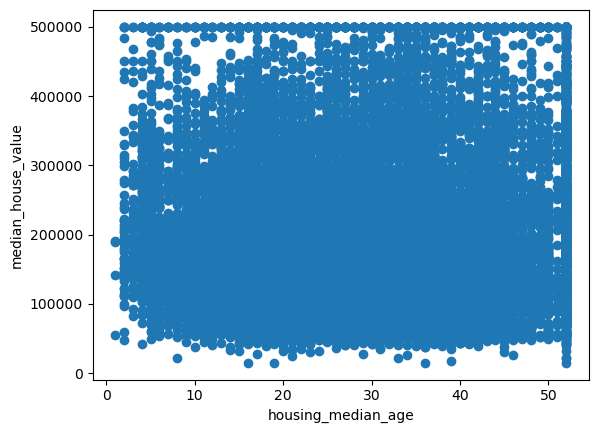

For column: total_rooms
total_rooms


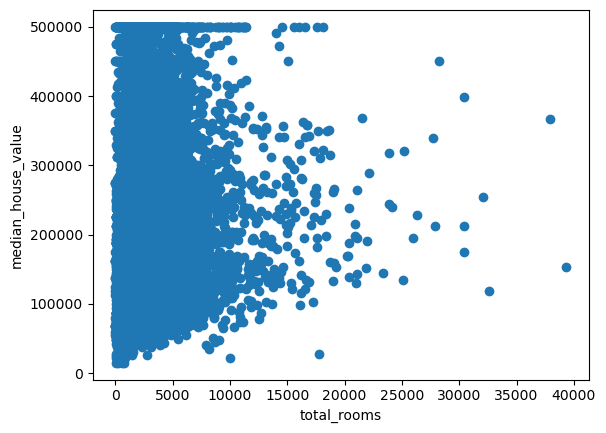

For column: total_bedrooms
total_bedrooms


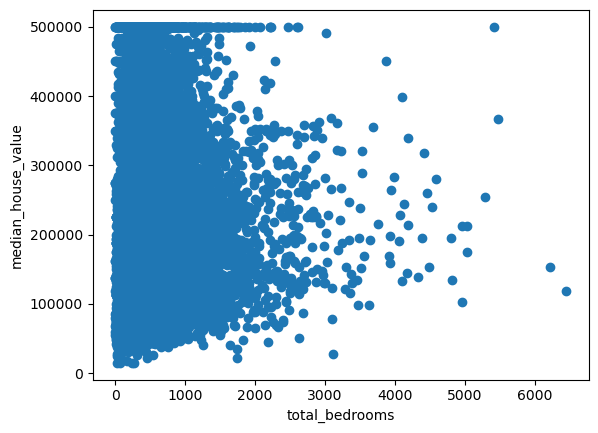

For column: population
population


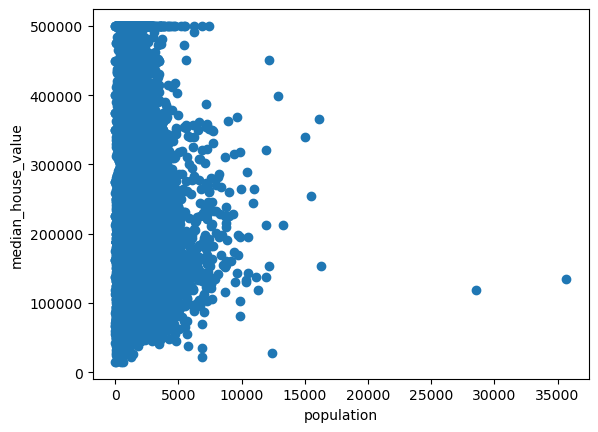

For column: households
households


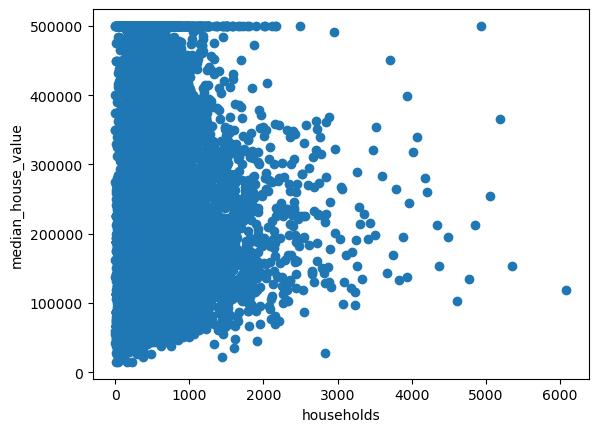

For column: median_income
median_income


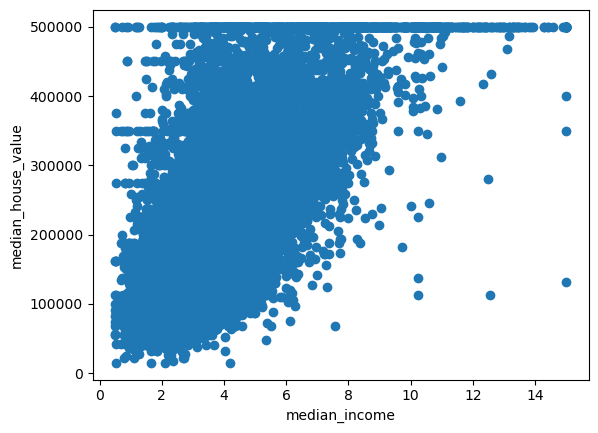

For column: median_house_value
median_house_value


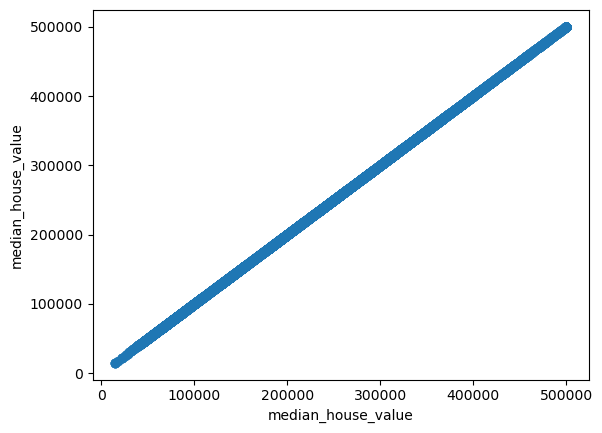

In [64]:
for c in col:
    
    print("For column:",c)
    sortcol = corr[c].sort_values(ascending=False)[1:].head(1)
    print(c)
    plt.scatter(x=data[c],y=data['median_house_value'])
    plt.xlabel(c)
    plt.ylabel('median_house_value')
    plt.show()    

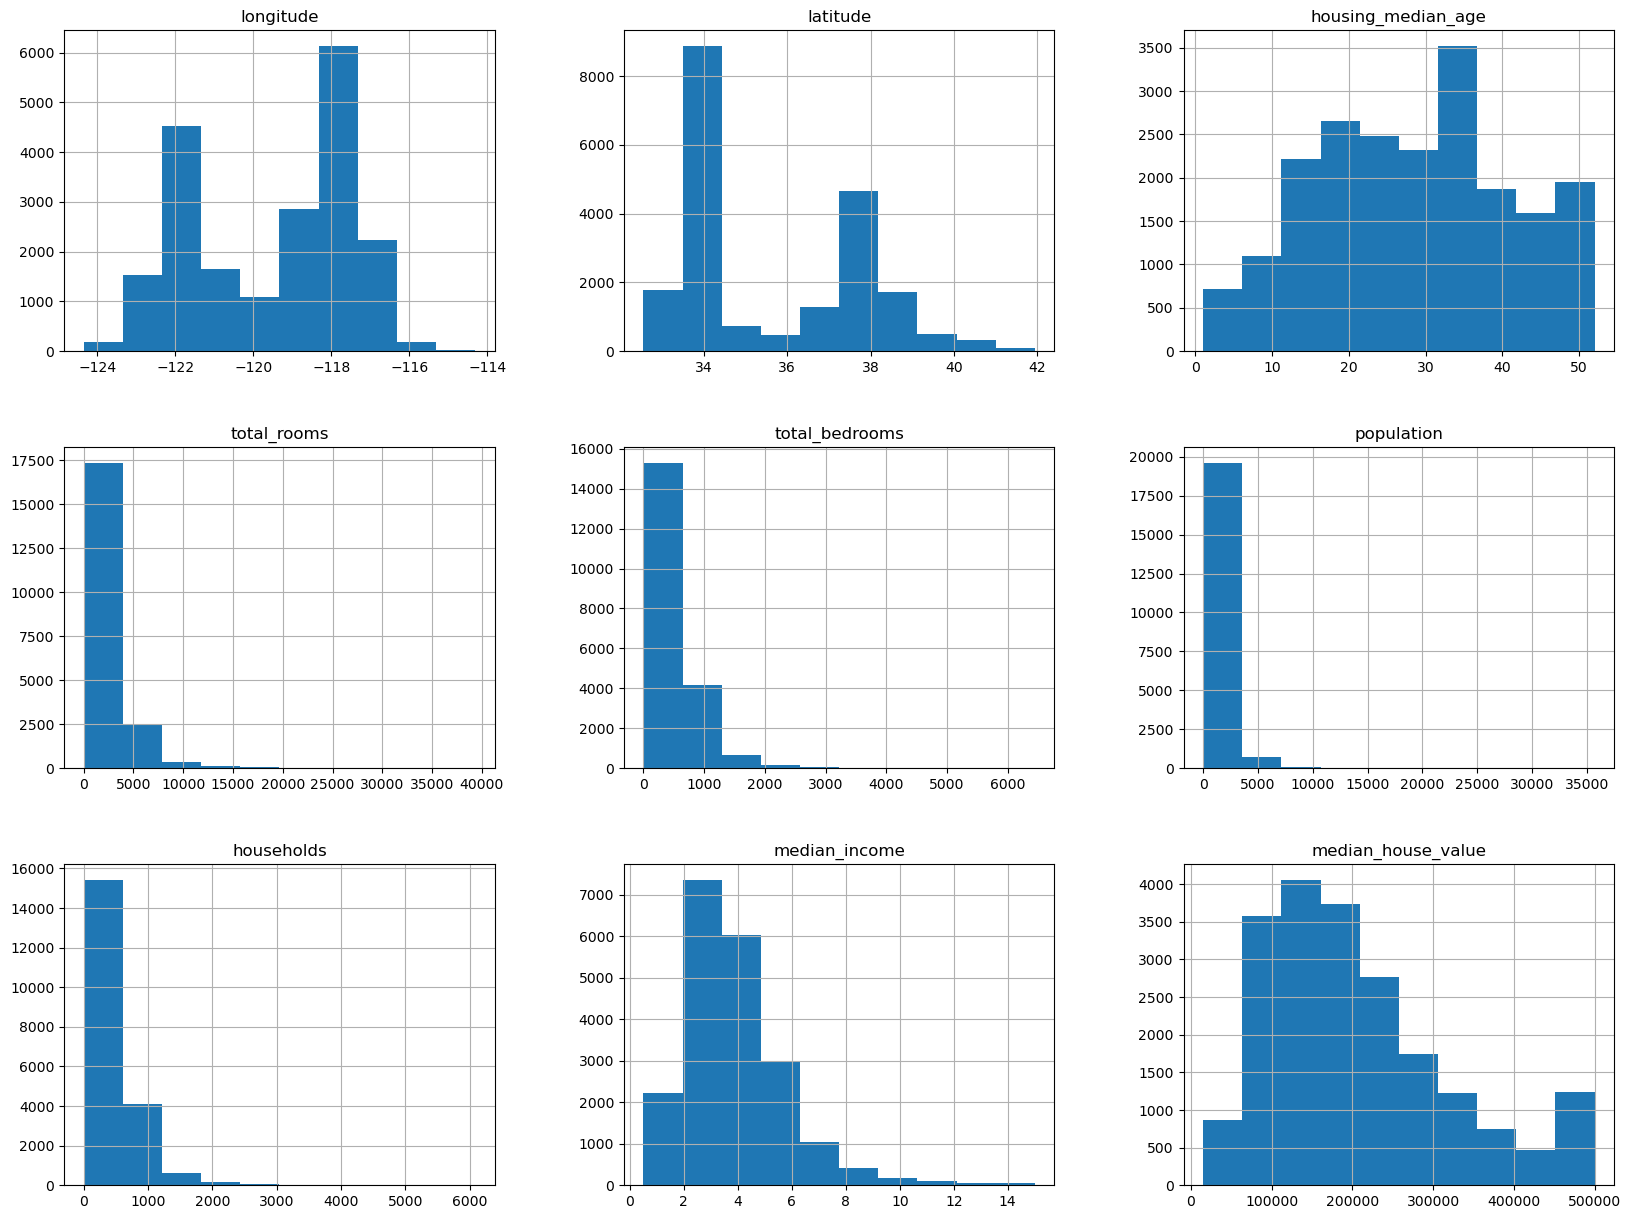

In [65]:
data.hist(figsize=(20,15))
plt.show()

In [66]:
data['income_cat'] = pd.cut(
    data['median_income'],
    bins = [0,1.5,3.0,4.5,6,np.inf],
    labels = [1,2,3,4,5]
)

In [67]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,5
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,5
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,5
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,4
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,3


In [68]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder()
data['ocean_proximity'] = encoder.fit_transform(data[['ocean_proximity']])
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,3.0,5
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,3.0,5
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,3.0,5
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,3.0,4
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,3.0,3


In [69]:
data['population_per_household'] = data['population']/data['households']
data['population_per_room'] = data['population']/data['total_rooms']


In [70]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat,population_per_household,population_per_room
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,3.0,5,2.555556,0.365909
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,3.0,5,2.109842,0.338217
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,3.0,5,2.802260,0.338105
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,3.0,4,2.547945,0.437991
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,3.0,3,2.181467,0.347265


In [71]:
from sklearn.model_selection import StratifiedShuffleSplit
strat= StratifiedShuffleSplit(n_splits=1,random_state=42,test_size=0.2)
for train_index,test_index in strat.split(data,data['income_cat']):
    strat_train = data.iloc[train_index]
    strat_test = data.iloc[test_index]
strat_test['income_cat'].value_counts()

income_cat
3    1431
2    1303
4     722
5     468
1     163
Name: count, dtype: int64

In [72]:
strat_train.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat,population_per_household,population_per_room
18052,-121.98,37.25,19.0,755.0,93.0,267.0,99.0,15.0000,500001.0,0.0,5,2.696970,0.353642
17555,-121.87,37.33,37.0,3137.0,685.0,2048.0,651.0,3.0156,270300.0,0.0,3,3.145929,0.652853
19195,-122.68,38.44,36.0,1311.0,259.0,648.0,268.0,3.4545,161200.0,0.0,3,2.417910,0.494279
17808,-121.87,37.41,17.0,3719.0,588.0,2089.0,561.0,6.7867,273700.0,0.0,5,3.723708,0.561710
10265,-117.85,33.90,25.0,1548.0,256.0,811.0,263.0,5.2037,242200.0,0.0,4,3.083650,0.523902


In [73]:
strat_train['income_cat'].value_counts()

income_cat
3    5725
2    5212
4    2889
5    1869
1     651
Name: count, dtype: int64

In [74]:
y_train = strat_train['median_house_value']
x_train = strat_train.drop(columns=['median_house_value'])
x_train.head()

y_test = strat_test['median_house_value']
x_test = strat_test.drop(columns=['median_house_value'])
x_test.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,income_cat,population_per_household,population_per_room
18143,-122.06,37.34,20.0,3435.0,593.0,1293.0,553.0,6.7578,0.0,5,2.338156,0.376419
8101,-118.21,33.80,41.0,1251.0,279.0,1053.0,278.0,3.2778,4.0,3,3.787770,0.841727
8313,-118.13,33.77,37.0,4365.0,926.0,1661.0,868.0,5.3046,4.0,4,1.913594,0.380527
8365,-118.35,33.97,26.0,1725.0,431.0,1130.0,404.0,3.2708,0.0,3,2.797030,0.655072
13188,-117.70,34.09,25.0,1719.0,331.0,1098.0,324.0,3.6250,1.0,3,3.388889,0.638743


In [75]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
pipe = Pipeline(
    [
        ('scaling',StandardScaler()),
        ('svm',SVR())
    ]
)

In [76]:
param_dist = {
    'svm__kernel' : ['rbf', 'sigmoid', 'poly', 'linear'],
    'svm__C' : np.logspace(start=-3, stop=1, num=5),
    'svm__gamma' : [0.0001, 0.001, 0.01, 0.1, 1, 10]
}


In [77]:
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=5,
    cv=5,
    random_state=42,
    n_jobs=-1
)

In [78]:
random_search.fit(x_train,y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('scaling', StandardScaler()),
                                             ('svm', SVR())]),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'svm__C': array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01]),
                                        'svm__gamma': [0.0001, 0.001, 0.01, 0.1,
                                                       1, 10],
                                        'svm__kernel': ['rbf', 'sigmoid',
                                                        'poly', 'linear']},
                   random_state=42)

In [79]:
model = random_search.best_estimator_


In [80]:
y_pred = model.predict(x_test)


In [81]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_pred,y_test)
print(mse)

13527437917.240273
